# Lab Sheet-08 · Project 2: Q-Learning based Maze Solver
**MCA III Semester (Session 2026–2027) – Mini Projects on Deep Learning and Reinforcement Learning**

**Objective:** build a Reinforcement Learning agent that learns the shortest path through a maze using **tabular Q-Learning** and reward shaping.

## Dataset
None – reinforcement learning learns from interaction with a simulated environment (a custom **Gymnasium** maze), so no Kaggle dataset is used.

**Workflow:** Define environment → Q-learning agent → Train → Learning curves → Extract policy/path → Verify vs BFS optimal → Hyper-parameter study → Save Q-table

### Q-Learning in one line
`Q(s,a) ← Q(s,a) + α [ r + γ · max_a' Q(s',a') − Q(s,a) ]`  with ε-greedy exploration (ε decays from 1.0 to a small floor).

In [1]:
# !pip install -q gymnasium numpy matplotlib pandas joblib
import time, joblib
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import gymnasium as gym
from gymnasium import spaces

SEED = 42

## 1. The maze environment
`#` wall · `.` free cell · `S` start · `G` goal.

| Item | Design |
|---|---|
| State | cell index `row * n_cols + col` (Discrete) |
| Actions | 0=Up, 1=Right, 2=Down, 3=Left |
| Reward | **−1** per step (encourages short paths) · **−5** for bumping into a wall/border (agent stays) · **+100** on reaching the goal |
| Episode ends | goal reached (terminated) or max steps (truncated) |

In [2]:
MAZE = [
    "S.#.......",
    "..#.####..",
    "..#....#..",
    ".####..#.#",
    "......##..",
    ".####.....",
    ".#..#.###.",
    ".#.##...#.",
    ".#....#.#.",
    "...##.#..G",
]


class MazeEnv(gym.Env):
    metadata = {"render_modes": ["ansi"]}
    MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]  # up, right, down, left

    def __init__(self, layout=MAZE, max_steps=200, step_r=-1.0, wall_r=-5.0, goal_r=100.0):
        super().__init__()
        self.grid = np.array([list(r) for r in layout])
        self.n_rows, self.n_cols = self.grid.shape
        self.start = tuple(np.argwhere(self.grid == "S")[0])
        self.goal = tuple(np.argwhere(self.grid == "G")[0])
        self.max_steps, self.step_r, self.wall_r, self.goal_r = max_steps, step_r, wall_r, goal_r
        self.observation_space = spaces.Discrete(self.n_rows * self.n_cols)
        self.action_space = spaces.Discrete(4)

    def _s(self, pos):
        return pos[0] * self.n_cols + pos[1]

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.pos, self.t = self.start, 0
        return self._s(self.pos), {}

    def step(self, action):
        dr, dc = self.MOVES[action]
        r, c = self.pos[0] + dr, self.pos[1] + dc
        self.t += 1
        if not (0 <= r < self.n_rows and 0 <= c < self.n_cols) or self.grid[r, c] == "#":
            reward = self.wall_r                      # bump: stay in place
        else:
            self.pos = (r, c)
            reward = self.step_r
        terminated = self.pos == self.goal
        if terminated:
            reward = self.goal_r
        truncated = (not terminated) and self.t >= self.max_steps
        return self._s(self.pos), reward, terminated, truncated, {}


env = MazeEnv()
print("Maze", env.grid.shape, "| start", env.start, "| goal", env.goal,
      "| states", env.observation_space.n, "| actions", env.action_space.n)

Maze (10, 10) | start (np.int64(0), np.int64(0)) | goal (np.int64(9), np.int64(9)) | states 100 | actions 4


### Ground truth: shortest path with Breadth-First Search
Used only to **verify** that Q-learning found the true optimum (the agent never sees it).

Optimal number of steps (BFS): 18


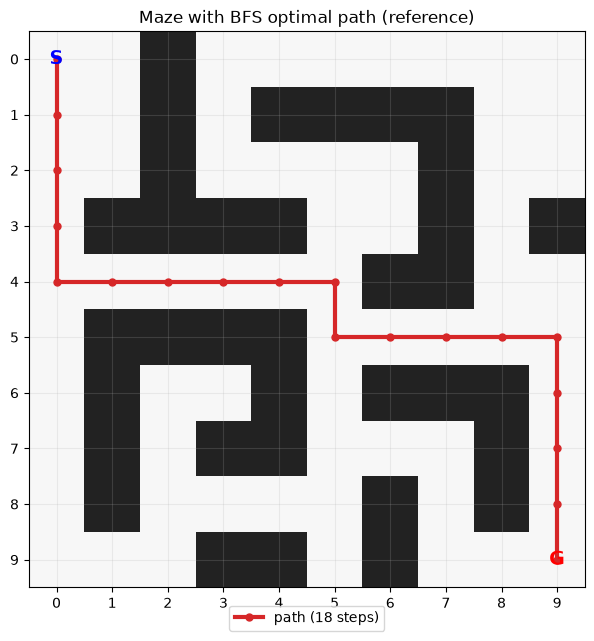

In [3]:
def bfs_shortest(env):
    q, seen = deque([(env.start, [env.start])]), {env.start}
    while q:
        pos, path = q.popleft()
        if pos == env.goal:
            return path
        for dr, dc in env.MOVES:
            nxt = (pos[0] + dr, pos[1] + dc)
            if 0 <= nxt[0] < env.n_rows and 0 <= nxt[1] < env.n_cols and env.grid[nxt] != "#" and nxt not in seen:
                seen.add(nxt); q.append((nxt, path + [nxt]))
    return None

opt_path = bfs_shortest(env)
assert opt_path is not None, "maze is not solvable"
OPT_STEPS = len(opt_path) - 1
print("Optimal number of steps (BFS):", OPT_STEPS)


def draw_maze(env, path=None, Q=None, title="Maze"):
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    num = (env.grid == "#").astype(int)
    ax.imshow(num, cmap=ListedColormap(["#f7f7f7", "#222222"]))
    if Q is not None:
        v = np.array([Q[s].max() for s in range(Q.shape[0])]).reshape(env.n_rows, env.n_cols)
        v = np.where(env.grid == "#", np.nan, v)
        im = ax.imshow(v, cmap="YlGn", alpha=.8); plt.colorbar(im, ax=ax, fraction=.046, label="max Q(s,·)")
        arrows = ["↑", "→", "↓", "←"]
        for r in range(env.n_rows):
            for c in range(env.n_cols):
                if env.grid[r, c] != "#" and (r, c) != env.goal:
                    ax.text(c, r, arrows[int(Q[r * env.n_cols + c].argmax())], ha="center", va="center", fontsize=11, color="#444")
    if path:
        ys, xs = zip(*path); ax.plot(xs, ys, "-o", color="#d62728", lw=3, ms=5, label=f"path ({len(path) - 1} steps)")
        ax.legend(loc="upper center", bbox_to_anchor=(.5, -.02))
    ax.text(env.start[1], env.start[0], "S", ha="center", va="center", color="blue", weight="bold", fontsize=14)
    ax.text(env.goal[1], env.goal[0], "G", ha="center", va="center", color="red", weight="bold", fontsize=14)
    ax.set_xticks(range(env.n_cols)); ax.set_yticks(range(env.n_rows)); ax.set_title(title); ax.grid(True, alpha=.2)
    plt.tight_layout(); plt.show()

draw_maze(env, opt_path, title="Maze with BFS optimal path (reference)")

## 2. Q-Learning agent

In [4]:
def train_q_learning(env, episodes=3000, alpha=0.1, gamma=0.99, eps_start=1.0, eps_min=0.05, eps_decay=0.998, seed=SEED):
    rng = np.random.default_rng(seed)
    nS, nA = env.observation_space.n, env.action_space.n
    Q = np.zeros((nS, nA))
    eps = eps_start
    log = {"reward": [], "steps": [], "success": [], "epsilon": []}
    for ep in range(episodes):
        s, _ = env.reset(seed=int(rng.integers(1e9)))
        total, done, steps = 0.0, False, 0
        while not done:
            a = int(rng.integers(nA)) if rng.random() < eps else int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))
            s2, r, terminated, truncated, _ = env.step(a)
            # Q-learning update (off-policy: bootstraps on the greedy next action; no bootstrap at terminal state)
            target = r + (0.0 if terminated else gamma * Q[s2].max())
            Q[s, a] += alpha * (target - Q[s, a])
            s, total, steps, done = s2, total + r, steps + 1, terminated or truncated
        eps = max(eps_min, eps * eps_decay)
        log["reward"].append(total); log["steps"].append(steps); log["success"].append(int(terminated)); log["epsilon"].append(eps)
    return Q, pd.DataFrame(log)


def greedy_path(env, Q, max_steps=200):
    s, _ = env.reset(); path = [env.start]
    for _ in range(max_steps):
        s, _, term, trunc, _ = env.step(int(Q[s].argmax())); path.append(env.pos)
        if term or trunc:
            break
    return path, env.pos == env.goal


t0 = time.time()
Q, log = train_q_learning(env)
print(f"Trained 3000 episodes in {time.time() - t0:.1f}s")

Trained 3000 episodes in 6.0s


## 3. Learning curves

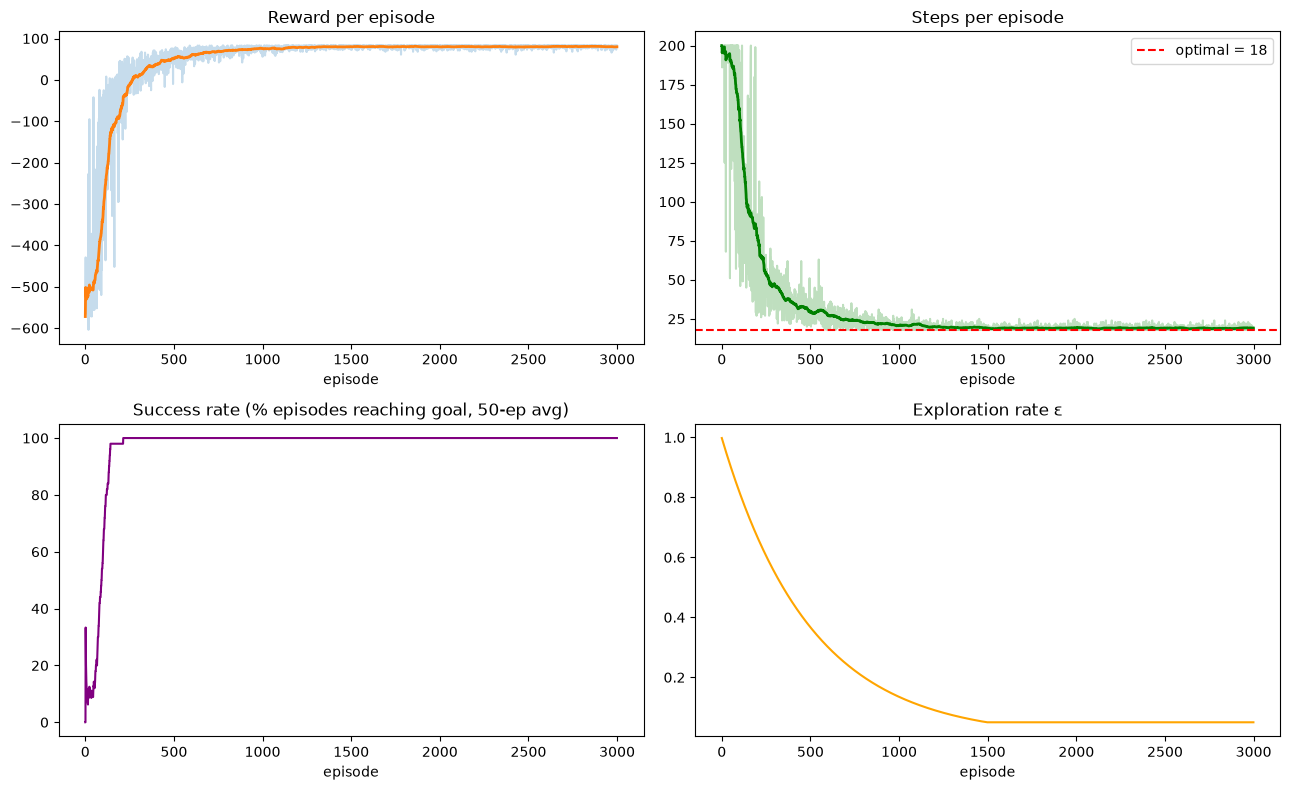

In [5]:
def smooth(x, w=50):
    return pd.Series(x).rolling(w, min_periods=1).mean()

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].plot(log["reward"], alpha=.25); axes[0, 0].plot(smooth(log["reward"]), lw=2); axes[0, 0].set_title("Reward per episode")
axes[0, 1].plot(log["steps"], alpha=.25, color="g"); axes[0, 1].plot(smooth(log["steps"]), lw=2, color="g")
axes[0, 1].axhline(OPT_STEPS, color="r", ls="--", label=f"optimal = {OPT_STEPS}"); axes[0, 1].set_title("Steps per episode"); axes[0, 1].legend()
axes[1, 0].plot(smooth(log["success"]) * 100, color="purple"); axes[1, 0].set_title("Success rate (% episodes reaching goal, 50-ep avg)")
axes[1, 1].plot(log["epsilon"], color="orange"); axes[1, 1].set_title("Exploration rate ε")
for a in axes.ravel(): a.set_xlabel("episode")
plt.tight_layout(); plt.savefig("maze_learning_curves.png", dpi=130); plt.show()

**Reading:** reward rises and steps fall as the agent shifts from exploration to exploitation; the success rate saturating near 100 % and steps converging to the dashed line shows it found the shortest path.

## 4. Learned policy and path

Reached goal: True | steps: 18 | optimal (BFS): 18 | OPTIMAL


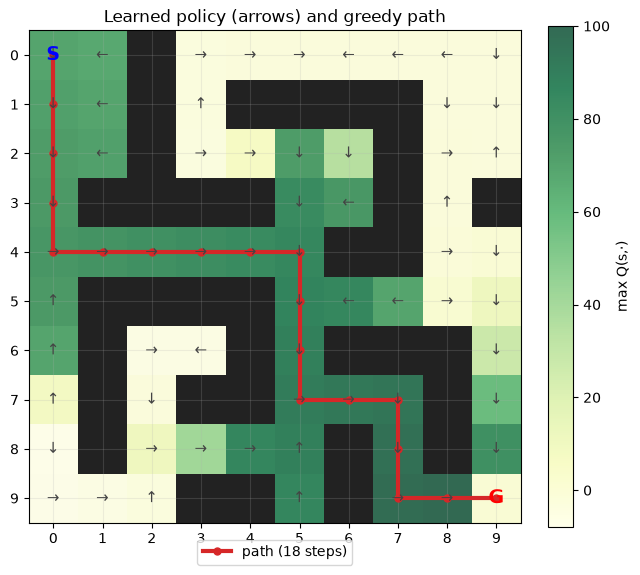

In [6]:
path, reached = greedy_path(env, Q)
print(f"Reached goal: {reached} | steps: {len(path) - 1} | optimal (BFS): {OPT_STEPS} | "
      f"{'OPTIMAL' if reached and len(path) - 1 == OPT_STEPS else 'sub-optimal'}")
draw_maze(env, path, Q, title="Learned policy (arrows) and greedy path")

## 5. Compare results: random agent vs Q-learning vs optimal

In [7]:
def evaluate(env, policy, n=200):
    succ, steps, rew = 0, [], []
    for i in range(n):
        s, _ = env.reset(seed=i); done, tot, k = False, 0, 0
        while not done:
            s, r, te, tr, _ = env.step(policy(s)); tot += r; k += 1; done = te or tr
        succ += te; steps.append(k); rew.append(tot)
    return succ / n * 100, np.mean(steps), np.mean(rew)

rng = np.random.default_rng(0)
rnd = evaluate(env, lambda s: int(rng.integers(4)))
ql = evaluate(env, lambda s: int(Q[s].argmax()))
cmp = pd.DataFrame({"Success %": [rnd[0], ql[0], 100.0], "Avg steps": [rnd[1], ql[1], OPT_STEPS],
                    "Avg reward": [rnd[2], ql[2], 100 - (OPT_STEPS - 1)]},
                   index=["Random agent", "Q-learning (greedy)", "BFS optimal (reference)"])
display(cmp.round(2))

,Success %,Avg steps,Avg reward
Random agent,5.0,196.66,-520.68
Q-learning (greedy),100.0,18.00,83.00
BFS optimal (reference),100.0,18.00,83.00


## 6. Hyper-parameter study (α, γ, ε-decay)
Each setting is trained with 3 seeds; we report mean convergence speed (first episode where the 50-episode success rate ≥ 95 %) and final greedy-path optimality.

,Config,Episodes to 95% success,Optimal path found (of 3 seeds)
0,"baseline (α=.1, γ=.99, decay=.998)",147.0,3
1,low α=.01,346.0,3
2,high α=.5,139.0,3
3,low γ=.80,150.0,3
4,fast ε decay=.99,90.0,3
5,slow ε decay=.9995,468.0,3


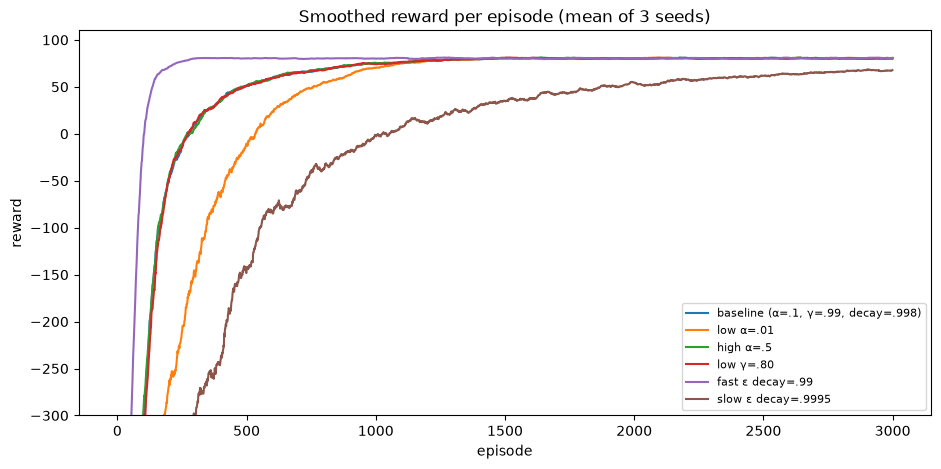

In [8]:
configs = {
    "baseline (α=.1, γ=.99, decay=.998)": dict(),
    "low α=.01":                         dict(alpha=0.01),
    "high α=.5":                         dict(alpha=0.5),
    "low γ=.80":                         dict(gamma=0.80),
    "fast ε decay=.99":                  dict(eps_decay=0.99),
    "slow ε decay=.9995":                dict(eps_decay=0.9995),
}
rows, curves = [], {}
for name, kw in configs.items():
    conv, opt, curve = [], [], []
    for sd in range(3):
        Qk, lg = train_q_learning(MazeEnv(), episodes=3000, seed=sd, **kw)
        sr = smooth(lg["success"]); hit = np.where(sr >= .95)[0]
        conv.append(hit[0] if len(hit) else np.nan)
        p, ok = greedy_path(MazeEnv(), Qk); opt.append(int(ok and len(p) - 1 == OPT_STEPS)); curve.append(smooth(lg["reward"]).values)
    curves[name] = np.mean(curve, axis=0)
    rows.append({"Config": name, "Episodes to 95% success": np.nanmean(conv), "Optimal path found (of 3 seeds)": sum(opt)})
hp = pd.DataFrame(rows); display(hp.round(0))
plt.figure(figsize=(11, 5))
for n_, c in curves.items(): plt.plot(c, label=n_)
plt.legend(fontsize=8); plt.title("Smoothed reward per episode (mean of 3 seeds)"); plt.xlabel("episode"); plt.ylabel("reward"); plt.ylim(-300, 110); plt.show()

## 7. Save the trained agent

In [9]:
np.save("maze_q_table.npy", Q)
joblib.dump({"Q": Q, "maze": MAZE, "hyperparameters": dict(alpha=0.1, gamma=0.99, eps_min=0.05, eps_decay=0.998, episodes=3000)}, "maze_q_agent.joblib")
Q2 = np.load("maze_q_table.npy"); p2, ok2 = greedy_path(MazeEnv(), Q2)
print("Saved maze_q_table.npy & maze_q_agent.joblib | reloaded agent solves maze:", ok2, "in", len(p2) - 1, "steps")

Saved maze_q_table.npy & maze_q_agent.joblib | reloaded agent solves maze: True in 18 steps


## 8. Observations
* **Reward design matters:** the −1 step cost pushes the agent toward the *shortest* route, the −5 wall penalty stops wasteful bumping, +100 gives a strong goal signal.
* **Exploration vs exploitation:** ε-greedy with decay explores early and exploits later. In this small maze every setting eventually found the optimal path; faster ε-decay converged earliest (≈90 episodes to 95 % success) while slow decay (0.9995) needed ≈5× more episodes. In larger or trickier mazes, decaying too fast risks locking in a sub-optimal route.
* **Learning rate α:** α = 0.01 was clearly the slowest (≈350 episodes vs ≈140–150 for α = 0.1–0.5); a large α is fine in this deterministic maze but would be noisy in stochastic environments. **Discount γ:** with γ = 0.8 convergence was similar here because the maze is short (18 steps), but low γ makes the agent short-sighted on longer tasks. *(Numbers are from one run of the study in §6 – yours may differ slightly.)*
* Q-learning is **off-policy** (target uses max over next actions) and **model-free** (no knowledge of the maze layout). The BFS check confirms the learned greedy path equals the true shortest path.
* **Limitation:** a Q-table scales poorly to large state spaces → *Deep Q-Networks (DQN)* are the natural extension (links to Project 1: neural network as a function approximator).